# Sub-etapa 1.2 · Obtención y preparación de datos: LabWalks (LTMM, PhysioNet)

**Proyecto:** Análisis de marcha y clasificación de riesgo de caída en adultos mayores (Línea 1, Proyecto 1).

**Objetivo de este notebook:** cargar las caminatas de laboratorio (*LabWalks*) de la base Long Term Movement Monitoring [Weiss et al., 2013], revisar su calidad, limpiarlas, calcular variables de marcha y hacer un análisis exploratorio de datos (EDA) que compare a las personas que caen con las que no caen.

**Productos que genera:**

| Archivo | Contenido |
|---|---|
| `datos/procesados/labwalks_calidad.csv` | Control de calidad de cada registro |
| `datos/procesados/labwalks_variables.csv` | **Dataset limpio:** una fila por persona, con etiqueta y variables de marcha |
| `datos/procesados/senales_limpias/*.csv` | Señales recortadas y filtradas, una por persona |
| `figuras/*.png` | Gráficos del EDA para el informe |

El significado de cada columna está en `DICCIONARIO_DE_DATOS.md`.

**Cómo ejecutarlo:** en Jupyter, menú *Kernel → Restart Kernel and Run All Cells*. Así se comprueba que el resultado no depende de pasos hechos a mano.

## 1. Configuración

Si falta alguna librería, instálala una vez desde la terminal de Anaconda:

```
pip install wfdb scipy pandas matplotlib openpyxl
```

Ajusta las rutas si guardaste los datos en otro lugar. La estructura esperada es:

```
proyecto/
├── notebooks/01_EDA_LabWalks.ipynb   ← este archivo
├── datos/crudos/LabWalks/            ← los .hea y .dat (descargados con LabWalks Explorer)
├── datos/crudos/ClinicalDemogData_COFL.xlsx   (opcional)
├── datos/procesados/                 ← se crea sola
└── figuras/                          ← se crea sola
```

In [1]:
import platform
import re
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import wfdb
from scipy import signal, stats

# --- Rutas (cámbialas si tus datos están en otra parte) ---------------------
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CARPETA_LABWALKS = RAIZ / "datos" / "crudos" / "LabWalks"
PLANILLA_CLINICA = RAIZ / "datos" / "crudos" / "ClinicalDemogData_COFL.xlsx"
SALIDA = RAIZ / "datos" / "procesados"
FIGURAS = RAIZ / "figuras"

# --- Parámetros de limpieza (documentados en la sección 4) ------------------
RECORTE_S = 3.0          # segundos que se quitan al inicio y al final (arranque y frenado)
CORTE_RUIDO_HZ = 20.0    # filtro pasa bajo para quitar ruido
CORTE_PASOS_HZ = 3.0     # filtro pasa bajo para detectar pasos
DURACION_MIN_S = 20.0    # registros más cortos (ya recortados) se excluyen

SEMILLA = 42             # se usará igual en los modelos de la etapa 2
np.random.seed(SEMILLA)

SALIDA.mkdir(parents=True, exist_ok=True)
(SALIDA / "senales_limpias").mkdir(exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
COLORES = {"No cae": "#1f5f99", "Cae": "#b03a2e"}

print("Carpeta LabWalks:", CARPETA_LABWALKS, "| existe:", CARPETA_LABWALKS.is_dir())
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__} | wfdb {wfdb.__version__}")

Carpeta LabWalks: C:\Users\dark_\OneDrive - UNIVERSIDAD ANDRES BELLO\Unab\2026\Segundo Semestre\Integrador práctica I\Práctica_investigación\Fuentes\Jupyter Notebook\proyecto-marcha\datos\crudos\LabWalks | existe: True
Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0 | matplotlib 3.11.0 | wfdb 4.3.1


## 2. Carga de los registros

Cada caminata son dos archivos: el `.hea` (texto con canales, frecuencia de muestreo, edad y sexo) y el `.dat` (las muestras). La librería `wfdb` lee ambos y entrega la señal ya en unidades físicas (g y °/s).

La etiqueta sale del nombre del archivo: `co` = *control*, no cae; `fl` = *faller*, dos o más caídas en el año previo. Es una **etiqueta retrospectiva** (ver brecha 1 del marco teórico).

In [2]:
def grupo_desde_nombre(nombre):
    n = nombre.lower()
    if n.startswith("co"):
        return "No cae", 0
    if n.startswith("fl"):
        return "Cae", 1
    return "Desconocido", np.nan


def leer_comentarios(comentarios):
    texto = " ".join(comentarios)
    edad = re.search(r"Age:\s*([\d.]+)", texto, re.I)
    sexo = re.search(r"Sex:\s*(\w+)", texto, re.I)
    return (float(edad.group(1)) if edad else np.nan, sexo.group(1).upper() if sexo else None)


def nombres_estandar(nombres, unidades):
    # Da un nombre fijo a cada canal (acc_v, acc_ml, acc_ap, giro_1, ...) para que el resto
    # del notebook no dependa de cómo se llamen los canales en el archivo.
    claves_acc = [("acc_v", ("v-", "vert")), ("acc_ml", ("ml", "medio")), ("acc_ap", ("ap", "antero"))]
    claves_giro = [("giro_yaw", ("yaw",)), ("giro_pitch", ("pitch",)), ("giro_roll", ("roll",))]
    salida, n_acc, n_giro = [], 0, 0
    for nombre, unidad in zip(nombres, unidades):
        nl, u = nombre.lower(), str(unidad).strip().lower()
        if "acc" in nl or u in ("g", "m/s^2", "m/s2", "m/s/s"):
            clave = next((k for k, pal in claves_acc if any(x in nl for x in pal)), None) or f"acc_{n_acc + 1}"
            n_acc += 1
        else:
            clave = next((k for k, pal in claves_giro if any(x in nl for x in pal)), None) or f"giro_{n_giro + 1}"
            n_giro += 1
        while clave in salida:
            clave += "_b"
        salida.append(clave)
    return salida


rutas = sorted(p.with_suffix("") for p in CARPETA_LABWALKS.glob("*.hea") if p.with_suffix(".dat").exists())
assert rutas, f"No encontré pares .hea/.dat en {CARPETA_LABWALKS}"

registros, inventario, errores = {}, [], []
for ruta in rutas:
    try:
        r = wfdb.rdrecord(str(ruta))
    except Exception as e:
        errores.append((ruta.name, str(e)))
        continue
    grupo, etiqueta = grupo_desde_nombre(r.record_name)
    edad, sexo = leer_comentarios(r.comments)
    registros[r.record_name] = r
    inventario.append({"registro": r.record_name, "grupo": grupo, "cae": etiqueta, "edad": edad,
                       "sexo": sexo, "fs_hz": r.fs, "muestras": r.sig_len,
                       "duracion_s": r.sig_len / r.fs, "canales": ", ".join(r.sig_name)})

inventario = pd.DataFrame(inventario)
print(f"Registros leídos: {len(inventario)}  |  con error: {len(errores)}")
for e in errores:
    print("  ", e)
inventario.head()

Registros leídos: 73  |  con error: 0


,registro,grupo,cae,edad,sexo,fs_hz,muestras,duracion_s,canales
0,co001_base,No cae,0,75.17,F,100,3801,38.01,"v-acceleration, ml-acceleration, ap-accelerati..."
1,co002_base,No cae,0,82.92,M,100,3601,36.01,"v-acceleration, ml-acceleration, ap-accelerati..."
2,co003_base,No cae,0,75.34,F,100,4201,42.01,"v-acceleration, ml-acceleration, ap-accelerati..."
3,co004_base,No cae,0,69.18,F,100,6901,69.01,"v-acceleration, ml-acceleration, ap-accelerati..."
4,co005_base,No cae,0,77.62,M,100,4901,49.01,"v-acceleration, ml-acceleration, ap-accelerati..."


In [3]:
# Canales tal como vienen en el archivo y el nombre que se usará en este notebook
ejemplo = next(iter(registros.values()))
canales = pd.DataFrame({"canal_en_archivo": ejemplo.sig_name, "unidad": ejemplo.units,
                        "nombre_en_notebook": nombres_estandar(ejemplo.sig_name, ejemplo.units)})
assert "acc_v" in canales["nombre_en_notebook"].values, "No encontré el canal de aceleración vertical: revisa la tabla"
distintos = [r.record_name for r in registros.values() if r.sig_name != ejemplo.sig_name]
print(f"Registros con canales distintos al primero: {len(distintos)}", distintos[:5])
canales

Registros con canales distintos al primero: 0 []


,canal_en_archivo,unidad,nombre_en_notebook
0,v-acceleration,g,acc_v
1,ml-acceleration,g,acc_ml
2,ap-acceleration,g,acc_ap
3,yaw-velocity,degrees/s,giro_yaw
4,pitch-velocity,degrees/s,giro_pitch
5,roll-velocity,degrees/s,giro_roll


### 2.1 Planilla clínica (opcional)

PhysioNet incluye `ClinicalDemogData_COFL.xlsx` con datos clínicos (por ejemplo, número de caídas y pruebas como el TUG). Esta celda la lee y muestra sus columnas. Como el formato de la planilla puede variar, **revisa la salida**: si la unión con los registros no funciona, cambia `COLUMNA_ID` por el nombre de la columna que identifica a cada persona.

In [4]:
COLUMNA_ID = None   # ej. "#" o "ID". Si es None se busca automáticamente

def clave_registro(valor, grupo_hoja=""):
    # Convierte 'CO001', 'co1', '1' (+ hoja 'FL') ... en 'co001' / 'fl001'
    s = str(valor).strip().lower()
    m = re.match(r"^(co|fl)?\D*0*(\d+)", s)
    if not m:
        return None
    prefijo = m.group(1) or ("fl" if "fl" in grupo_hoja.lower() else "co" if "co" in grupo_hoja.lower() else "")
    return f"{prefijo}{int(m.group(2)):03d}" if prefijo else None

clinica = None
if PLANILLA_CLINICA.exists():
    hojas = pd.read_excel(PLANILLA_CLINICA, sheet_name=None)
    partes = []
    for nombre_hoja, df in hojas.items():
        print(f"Hoja '{nombre_hoja}': {df.shape[0]} filas | columnas: {list(df.columns)}")
        col = COLUMNA_ID or next((c for c in df.columns if str(c).strip().lower() in
                                  ("#", "id", "subject", "sujeto", "record", "registro")), df.columns[0])
        df = df.copy()
        df["clave"] = [clave_registro(v, nombre_hoja) for v in df[col]]
        partes.append(df)
    clinica = pd.concat(partes, ignore_index=True).dropna(subset=["clave"]).drop_duplicates("clave")
    inventario["clave"] = inventario["registro"].str.extract(r"^((?:co|fl)\d{3})", expand=False)
    unidos = inventario["clave"].isin(clinica["clave"]).sum()
    print(f"\nRegistros con datos clínicos: {unidos} de {len(inventario)}")
    if unidos < len(inventario) / 2:
        print("⚠ La unión encontró pocos registros: revisa COLUMNA_ID y el formato de los identificadores.")
        clinica = None
else:
    print("No está la planilla clínica; se sigue solo con edad y sexo del encabezado.")

Hoja 'Controls': 44 filas | columnas: ['#', 'Date of Evaluation', 'GCS (Neurotrax)', 'EFI (Exe. Func. Index)', 'Gender(1-female, 0-male)', 'Age', 'Year Fall ', '6 Months Fall', ' yr almost', 'GDS', 'ABC Tot %', 'SF-36', 'PASE', 'MMSE', 'MoCa', 'FAB', 'TMTa', 'TMTb', 'TUG', 'FSST', 'BERG', 'DGI', 'DGI stairs', 'base(velocity)', 's3(velocity)', 'feet close eyes open', 'feet close eyes closed', 'tandem_eyes_open', 'tandem_eyes_closed']
Hoja 'Fallers': 33 filas | columnas: ['#', 'Date of Evaluation', 'GCS (Neurotrax)', 'EFI (Exe. Func. Index)', 'Gender(0-male,1-female)', 'Age', 'Year Fall ', '6 Months Fall', ' yr almost', 'GDS', 'ABC Tot %', 'SF-36', 'PASE', 'MMSE', 'MoCa', 'FAB', 'TMTa', 'TMTb', 'TUG', 'FSST', 'BERG', 'DGI', 'DGI stairs', 'base(velocity)', 's3(velocity)', 'feet close eyes open', 'feet close eyes closed', 'tandem_eyes_open', 'tandem_eyes_closed']
Hoja 'Legend': 22 filas | columnas: ['Measure', 'Explanation', 'Unnamed: 2']

Registros con datos clínicos: 69 de 73


## 3. Control de calidad

Antes de limpiar se revisa cada registro con criterios objetivos. Un registro se **excluye** solo si tiene datos faltantes, un canal plano o es demasiado corto; los demás avisos se **marcan** pero el registro se conserva.

| Revisión | Por qué importa | Acción |
|---|---|---|
| Frecuencia de muestreo distinta de 100 Hz | Cambia todas las variables en el tiempo | Marcar |
| Valores faltantes (NaN) | El filtrado falla | Excluir |
| Canal plano | Sensor desconectado | Excluir |
| Saturación (>1 % de muestras en el máximo) | El sensor llegó a su límite | Marcar |
| Media del eje vertical fuera de 0,8–1,2 g | Sensor girado o mal ubicado | Marcar |
| Duración útil < 20 s | Muy pocos pasos para medir variabilidad | Excluir |

In [5]:
def revisar(r):
    x = r.p_signal
    sat = max(np.mean(np.isclose(np.abs(x[:, i]), np.nanmax(np.abs(x[:, i])))) for i in range(x.shape[1]))
    i_v = nombres_estandar(r.sig_name, r.units).index("acc_v")
    dur_util = r.sig_len / r.fs - 2 * RECORTE_S
    return {
        "registro": r.record_name,
        "fs_ok": r.fs == 100,
        "nan": int(np.isnan(x).sum()),
        "canal_plano": bool((np.nanstd(x, axis=0) < 1e-6).any()),
        "saturacion_pct": round(100 * sat, 2),
        "media_vertical_g": round(float(np.nanmean(x[:, i_v])), 3),
        "duracion_util_s": round(dur_util, 1),
    }

calidad = pd.DataFrame(revisar(r) for r in registros.values())
calidad["aviso_saturacion"] = calidad["saturacion_pct"] > 1
calidad["aviso_orientacion"] = ~calidad["media_vertical_g"].abs().between(0.8, 1.2)
calidad["excluir"] = (calidad["nan"] > 0) | calidad["canal_plano"] | (calidad["duracion_util_s"] < DURACION_MIN_S)
calidad["motivo"] = np.select(
    [calidad["nan"] > 0, calidad["canal_plano"], calidad["duracion_util_s"] < DURACION_MIN_S],
    ["datos faltantes", "canal plano", "muy corto"], default="")
calidad.to_csv(SALIDA / "labwalks_calidad.csv", index=False)

print(f"Excluidos: {calidad['excluir'].sum()} | aviso saturación: {calidad['aviso_saturacion'].sum()} | "
      f"aviso orientación: {calidad['aviso_orientacion'].sum()} | fs distinta de 100 Hz: {(~calidad['fs_ok']).sum()}")
calidad[calidad[["excluir", "aviso_saturacion", "aviso_orientacion"]].any(axis=1) | ~calidad["fs_ok"]]

Excluidos: 0 | aviso saturación: 0 | aviso orientación: 0 | fs distinta de 100 Hz: 0


,registro,fs_ok,nan,canal_plano,saturacion_pct,media_vertical_g,duracion_util_s,aviso_saturacion,aviso_orientacion,excluir,motivo


## 4. Limpieza de las señales

Pasos, en este orden:

1. **Recorte:** se quitan los primeros y últimos 3 s, donde la persona arranca y frena, porque no representan su marcha normal.
2. **Filtro pasa bajo de 20 Hz** (Butterworth de 4.º orden, aplicado hacia adelante y hacia atrás para no desfasar la señal): la marcha tiene casi toda su energía bajo 10–15 Hz, así que lo que queda sobre 20 Hz es ruido.
3. **Quitar la gravedad del eje vertical:** se resta el promedio, para que la señal oscile en torno a 0.

Para detectar pasos se usa además una versión más suave (pasa bajo de 3 Hz) del eje vertical, donde cada paso queda como un solo máximo.

In [6]:
def pasabajo(x, fs, fc, orden=4):
    b, a = signal.butter(orden, fc / (fs / 2), btype="low")
    return signal.filtfilt(b, a, x, axis=0)


def limpiar(r):
    fs = r.fs
    n = int(RECORTE_S * fs)
    x = r.p_signal[n:-n] if r.sig_len > 2 * n else r.p_signal
    x = pasabajo(x, fs, CORTE_RUIDO_HZ)
    df = pd.DataFrame(x, columns=nombres_estandar(r.sig_name, r.units))
    df["acc_v"] -= df["acc_v"].mean()    # quitar gravedad
    df.insert(0, "tiempo_s", np.arange(len(df)) / fs)
    return df


validos = calidad.loc[~calidad["excluir"], "registro"].tolist()
limpias = {nombre: limpiar(registros[nombre]) for nombre in validos}
for nombre, df in limpias.items():
    df.to_csv(SALIDA / "senales_limpias" / f"{nombre}.csv", index=False, float_format="%.5f")
print(f"Señales limpias guardadas: {len(limpias)}")

Señales limpias guardadas: 73


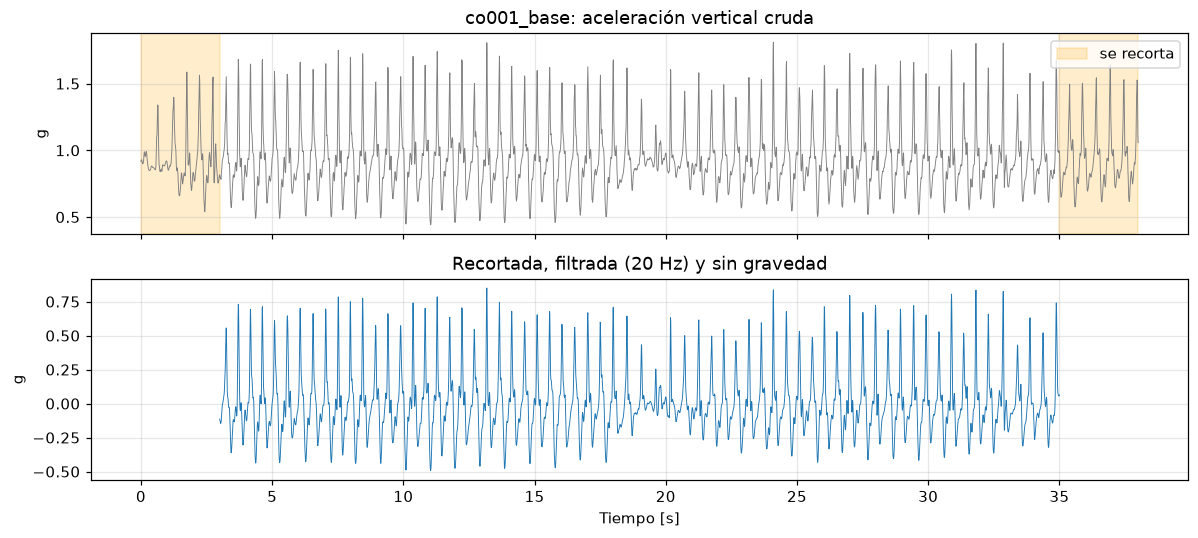

In [7]:
# Antes y después, en un registro de ejemplo
nombre = validos[0]
r = registros[nombre]
t_crudo = np.arange(r.sig_len) / r.fs
fig, ejes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ejes[0].plot(t_crudo, r.p_signal[:, nombres_estandar(r.sig_name, r.units).index("acc_v")], lw=0.6, color="gray")
ejes[0].axvspan(0, RECORTE_S, color="orange", alpha=0.2, label="se recorta")
ejes[0].axvspan(t_crudo[-1] - RECORTE_S, t_crudo[-1], color="orange", alpha=0.2)
ejes[0].set(title=f"{nombre}: aceleración vertical cruda", ylabel="g")
ejes[0].legend(loc="upper right")
ejes[1].plot(limpias[nombre]["tiempo_s"] + RECORTE_S, limpias[nombre]["acc_v"], lw=0.6)
ejes[1].set(title="Recortada, filtrada (20 Hz) y sin gravedad", xlabel="Tiempo [s]", ylabel="g")
fig.tight_layout()
fig.savefig(FIGURAS / "limpieza_antes_despues.png", dpi=150)

## 5. Variables de marcha

Con un solo sensor en la zona lumbar no se puede medir directamente la velocidad ni el largo de paso (habría que integrar la aceleración, lo que acumula error). Por eso se calculan las variables que la literatura obtiene de forma confiable desde el tronco:

* **Temporales:** número de pasos, cadencia, tiempo de paso y de zancada, y su **coeficiente de variación** (CV = σ/μ × 100). La variabilidad es uno de los mejores indicadores de riesgo [Hausdorff et al., 2001].
* **Regularidad y simetría** (método de autocorrelación de Moe-Nilssen y Helbostad, 2004): qué tanto se parece un paso al siguiente y una zancada a la siguiente. Weiss et al. encontraron menor regularidad en quienes caen.
* **Frecuenciales** (como en Weiss et al., 2013): frecuencia dominante, su amplitud y el ancho del pico en el espectro.
* **Intensidad:** valor RMS de cada eje de aceleración y de velocidad angular.

In [8]:
def detectar_pasos(v, fs):
    suave = pasabajo(v, fs, CORTE_PASOS_HZ)
    picos, _ = signal.find_peaks(suave, distance=int(0.3 * fs), prominence=0.3 * np.std(suave))
    return picos, suave


def autocorr(x):
    x = x - x.mean()
    ac = signal.correlate(x, x, mode="full", method="fft")[len(x) - 1:]
    return ac / ac[0]


def regularidad(v, fs):
    # d1 = pico de un paso, d2 = pico de una zancada (dos pasos)
    ac = autocorr(v)
    lags = np.arange(len(ac)) / fs
    picos, _ = signal.find_peaks(ac)
    candidatos = picos[(lags[picos] > 0.25) & (lags[picos] < 1.0)]
    if len(candidatos) == 0:
        return np.nan, np.nan, np.nan
    p1 = candidatos[np.argmax(ac[candidatos])]
    zona = picos[(picos > 1.5 * p1) & (picos < 2.5 * p1)]
    if len(zona) == 0:
        return ac[p1], np.nan, np.nan
    p2 = zona[np.argmax(ac[zona])]
    return ac[p1], ac[p2], ac[p1] / ac[p2]


def espectro(v, fs):
    f, p = signal.welch(v, fs=fs, nperseg=min(len(v), int(10 * fs)), nfft=8192)
    banda = (f >= 0.5) & (f <= 3.0)
    i = np.argmax(np.where(banda, p, 0))
    mitad = p[i] / 2
    izq = i
    while izq > 0 and p[izq] > mitad:
        izq -= 1
    der = i
    while der < len(p) - 1 and p[der] > mitad:
        der += 1
    return f[i], p[i], f[der] - f[izq]


def variables(nombre, df, fs):
    v = df["acc_v"].to_numpy()
    picos, _ = detectar_pasos(v, fs)
    t_paso = np.diff(picos) / fs
    t_zancada = (picos[2:] - picos[:-2]) / fs
    d1, d2, sim = regularidad(v, fs)
    f_dom, amp_dom, ancho = espectro(v, fs)
    cv = lambda x: 100 * np.std(x, ddof=1) / np.mean(x) if len(x) > 2 else np.nan
    fila = {
        "registro": nombre,
        "duracion_util_s": len(df) / fs,
        "n_pasos": len(picos),
        "cadencia_pasos_min": 60 / t_paso.mean() if len(t_paso) else np.nan,
        "tiempo_paso_s": t_paso.mean() if len(t_paso) else np.nan,
        "cv_tiempo_paso_pct": cv(t_paso),
        "tiempo_zancada_s": t_zancada.mean() if len(t_zancada) else np.nan,
        "cv_tiempo_zancada_pct": cv(t_zancada),
        "regularidad_paso": d1,
        "regularidad_zancada": d2,
        "simetria": sim,
        "frec_dominante_hz": f_dom,
        "amplitud_dominante": amp_dom,
        "ancho_pico_hz": ancho,
    }
    for col in df.columns.drop("tiempo_s"):
        fila[f"rms_{col}"] = np.sqrt(np.mean((df[col] - df[col].mean()) ** 2))
    return fila


tabla = pd.DataFrame(variables(n, df, registros[n].fs) for n, df in limpias.items())
tabla.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
duracion_util_s,73.0,45.147,20.618,24.010,36.010,41.010,49.010,162.010
n_pasos,73.0,83.110,39.637,46.000,66.000,73.000,83.000,322.000
cadencia_pasos_min,73.0,111.493,10.184,71.988,105.458,111.267,116.244,136.072
tiempo_paso_s,73.0,0.543,0.054,0.441,0.516,0.539,0.569,0.833
cv_tiempo_paso_pct,73.0,15.181,24.076,3.462,7.456,10.281,14.999,206.680
tiempo_zancada_s,73.0,1.086,0.109,0.882,1.032,1.081,1.138,1.675
cv_tiempo_zancada_pct,73.0,10.487,17.533,2.012,4.299,6.358,11.075,148.011
regularidad_paso,73.0,0.712,0.136,0.226,0.649,0.745,0.804,0.885
regularidad_zancada,73.0,0.694,0.133,0.196,0.655,0.726,0.773,0.885
simetria,73.0,1.037,0.134,0.553,0.970,1.031,1.123,1.297


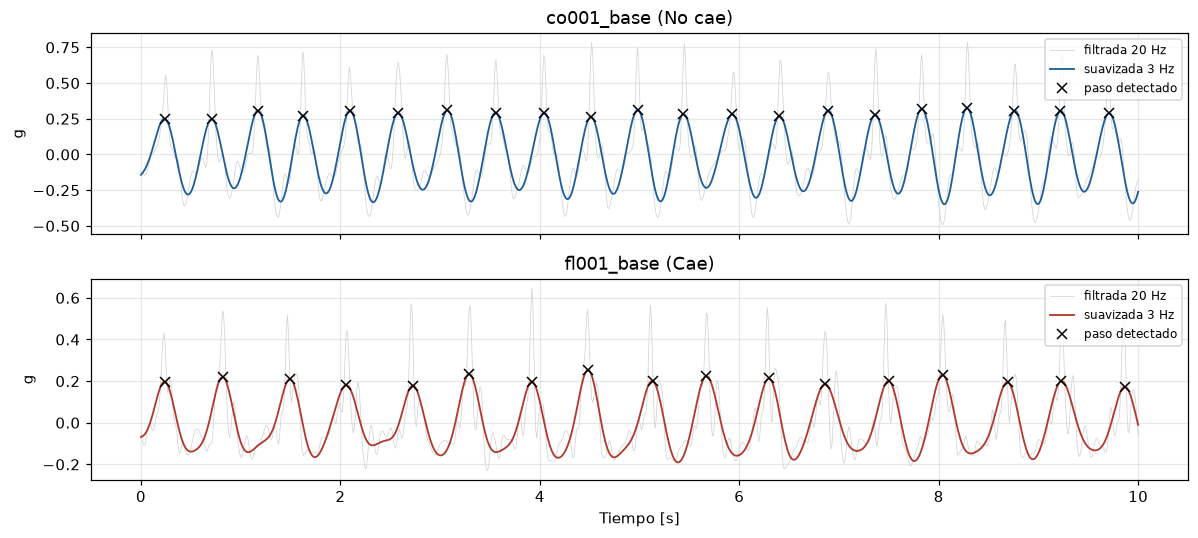

In [9]:
# Verificación visual de la detección de pasos (conviene revisar varios registros)
fig, ejes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ejemplos = [n for n in validos if n.startswith("co")][:1] + [n for n in validos if n.startswith("fl")][:1]
for eje, nombre in zip(ejes, ejemplos):
    df = limpias[nombre]
    fs = registros[nombre].fs
    picos, suave = detectar_pasos(df["acc_v"].to_numpy(), fs)
    m = df["tiempo_s"] <= 10
    eje.plot(df["tiempo_s"][m], df["acc_v"][m], lw=0.5, color="lightgray", label="filtrada 20 Hz")
    eje.plot(df["tiempo_s"][m], suave[m], lw=1.2, color=COLORES[grupo_desde_nombre(nombre)[0]], label="suavizada 3 Hz")
    p = picos[picos < m.sum()]
    eje.plot(df["tiempo_s"].iloc[p], suave[p], "kx", label="paso detectado")
    eje.set(title=f"{nombre} ({grupo_desde_nombre(nombre)[0]})", ylabel="g")
    eje.legend(loc="upper right", fontsize=8)
ejes[-1].set_xlabel("Tiempo [s]")
fig.tight_layout()
fig.savefig(FIGURAS / "deteccion_pasos.png", dpi=150)

### 5.1 Dataset limpio

Se une todo en una tabla con **una fila por persona**. Como cada persona tiene un solo registro, más adelante la validación cruzada separará naturalmente por sujeto y no habrá fuga de datos (*data leakage*).

In [10]:
dataset = inventario.drop(columns=["canales", "muestras", "duracion_s"]).merge(tabla, on="registro")
if clinica is not None:
    extra = clinica.drop(columns=[c for c in clinica.columns if c in dataset.columns and c != "clave"])
    dataset = dataset.merge(extra, on="clave", how="left")
dataset = dataset.drop(columns=["clave"], errors="ignore")

faltantes = dataset.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
print(faltantes[faltantes > 0].to_string() if faltantes.any() else "  ninguno")

dataset.to_csv(SALIDA / "labwalks_variables.csv", index=False, float_format="%.5f")
print(f"\nGuardado: {SALIDA / 'labwalks_variables.csv'}  ({dataset.shape[0]} filas × {dataset.shape[1]} columnas)")
dataset.head()

Valores faltantes por columna (solo las que tienen):
edad                         2
sexo                         1
#                            4
Date of Evaluation           4
GCS (Neurotrax)              8
EFI (Exe. Func. Index)       7
Gender(1-female, 0-male)    35
Age                          5
Year Fall                    5
6 Months Fall                6
 yr almost                   6
GDS                          7
ABC Tot %                    5
SF-36                        8
PASE                         6
MMSE                         4
MoCa                         6
FAB                          4
TMTa                         5
TMTb                         5
TUG                          4
FSST                         5
BERG                         4
DGI                          4
DGI stairs                   5
base(velocity)               4
s3(velocity)                 5
feet close eyes open         5
feet close eyes closed       6
tandem_eyes_open             7
tandem_eyes_close

,registro,grupo,cae,edad,sexo,fs_hz,duracion_util_s,n_pasos,cadencia_pasos_min,tiempo_paso_s,...,base(velocity),s3(velocity),feet close eyes open,feet close eyes closed,tandem_eyes_open,tandem_eyes_closed,"Gender(0-male,1-female)",Measure,Explanation,Unnamed: 2
0,co001_base,No cae,0,75.17,F,100,32.01,66,123.183828,0.487077,...,1.24,1.38,6.317,6.30,3.35,8.32,NaN,NaN,NaN,NaN
1,co002_base,No cae,0,82.92,M,100,30.01,54,108.755130,0.551698,...,1.32,1.18,8.146,13.69,7.97,19.39,NaN,NaN,NaN,NaN
2,co003_base,No cae,0,75.34,F,100,36.01,70,117.015263,0.512754,...,1.15,1.31,6.737,14.08,8.51,13.71,NaN,NaN,NaN,NaN
3,co004_base,No cae,0,69.18,F,100,63.01,76,71.988482,0.833467,...,1.19,1.05,4.961,8.57,5.10,13.43,NaN,NaN,NaN,NaN
4,co005_base,No cae,0,77.62,M,100,43.01,68,95.464260,0.628507,...,1.08,1.16,4.245,6.93,4.75,15.53,NaN,NaN,NaN,NaN


## 6. Análisis exploratorio

### 6.1 Composición de la muestra

In [11]:
resumen = dataset.groupby("grupo").agg(
    personas=("registro", "count"),
    edad_media=("edad", "mean"), edad_de=("edad", "std"),
    mujeres=("sexo", lambda s: (s == "F").sum()),
    duracion_media_s=("duracion_util_s", "mean"))
resumen["pct_mujeres"] = 100 * resumen["mujeres"] / resumen["personas"]
display(resumen.round(1))

# ¿Los grupos difieren en edad o sexo? (posibles variables de confusión)
a, b = (dataset.loc[dataset["grupo"] == g, "edad"].dropna() for g in ("No cae", "Cae"))
print(f"Edad: Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}")
tabla_sexo = pd.crosstab(dataset["grupo"], dataset["sexo"])
print(f"Sexo: chi-cuadrado p = {stats.chi2_contingency(tabla_sexo)[1]:.3f}")

,personas,edad_media,edad_de,mujeres,duracion_media_s,pct_mujeres
grupo,,,,,,
Cae,35,77.8,5.0,22,51.8,62.9
No cae,38,78.6,4.9,24,39.1,63.2


Edad: Mann-Whitney p = 0.649
Sexo: chi-cuadrado p = 1.000


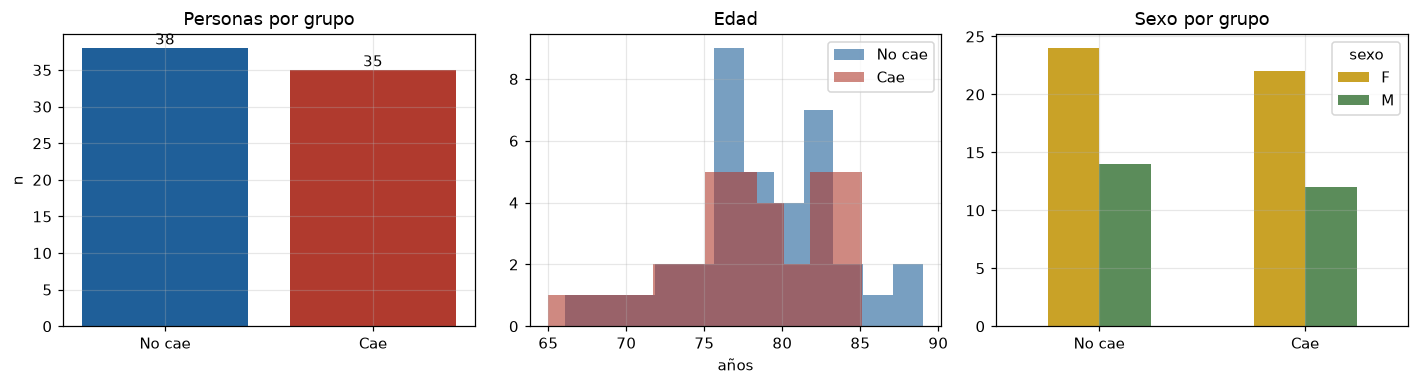

In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
conteo = dataset["grupo"].value_counts().reindex(["No cae", "Cae"])
ejes[0].bar(conteo.index, conteo.values, color=[COLORES[g] for g in conteo.index])
for i, v in enumerate(conteo.values):
    ejes[0].text(i, v, str(v), ha="center", va="bottom")
ejes[0].set(title="Personas por grupo", ylabel="n")
for g in ("No cae", "Cae"):
    ejes[1].hist(dataset.loc[dataset["grupo"] == g, "edad"].dropna(), bins=12, alpha=0.6, color=COLORES[g], label=g)
ejes[1].set(title="Edad", xlabel="años")
ejes[1].legend()
tabla_sexo.reindex(["No cae", "Cae"]).plot.bar(ax=ejes[2], rot=0, color=["#c9a227", "#5b8c5a"])
ejes[2].set(title="Sexo por grupo", xlabel="")
fig.tight_layout()
fig.savefig(FIGURAS / "muestra.png", dpi=150)

### 6.2 Señales y espectro por grupo

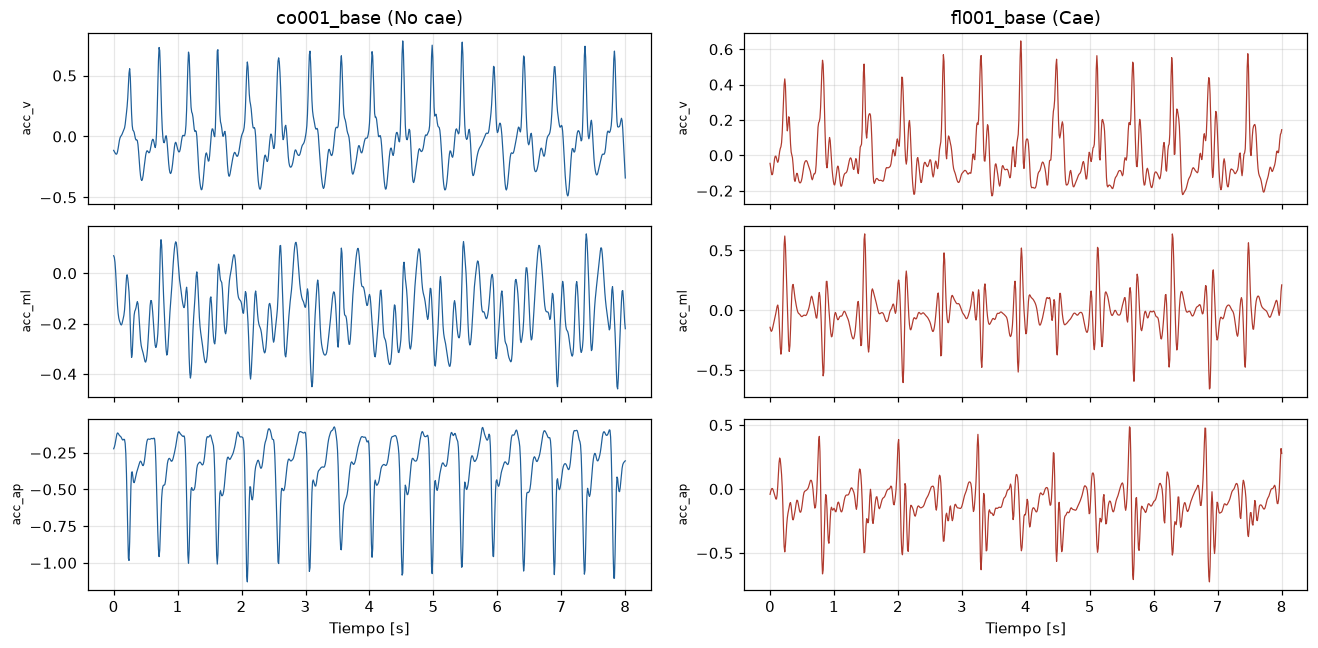

In [13]:
fig, ejes = plt.subplots(3, 2, figsize=(12, 6), sharex=True)
for j, nombre in enumerate(ejemplos):
    df = limpias[nombre]
    m = df["tiempo_s"] <= 8
    for i, col in enumerate([c for c in ["acc_v", "acc_ml", "acc_ap"] if c in df.columns][:3]):
        ejes[i, j].plot(df["tiempo_s"][m], df[col][m], lw=0.8, color=COLORES[grupo_desde_nombre(nombre)[0]])
        ejes[i, j].set_ylabel(f"{col}", fontsize=8)
    ejes[0, j].set_title(f"{nombre} ({grupo_desde_nombre(nombre)[0]})")
    ejes[-1, j].set_xlabel("Tiempo [s]")
fig.tight_layout()
fig.savefig(FIGURAS / "senales_ejemplo.png", dpi=150)

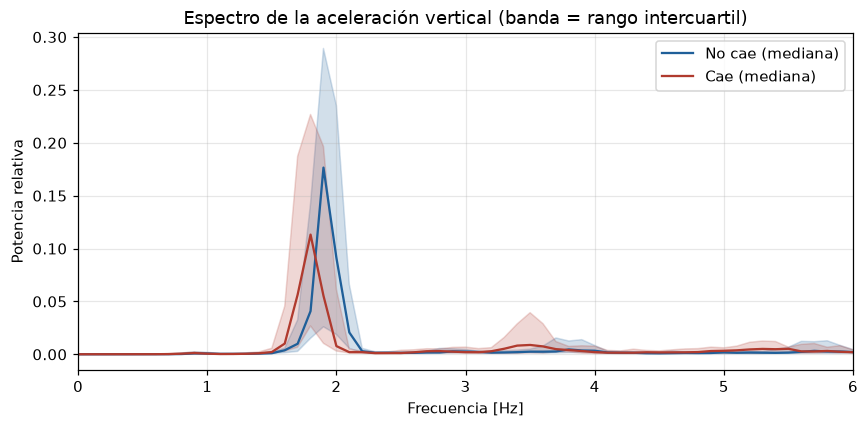

In [14]:
fig, eje = plt.subplots(figsize=(8, 4))
for g in ("No cae", "Cae"):
    espectros = []
    for nombre in dataset.loc[dataset["grupo"] == g, "registro"]:
        fs = registros[nombre].fs
        f, p = signal.welch(limpias[nombre]["acc_v"].to_numpy(), fs=fs, nperseg=int(10 * fs))
        espectros.append(p / p.sum())             # normalizado: compara forma, no intensidad
    espectros = np.array(espectros)
    eje.plot(f, np.median(espectros, axis=0), color=COLORES[g], label=f"{g} (mediana)")
    eje.fill_between(f, *np.percentile(espectros, [25, 75], axis=0), color=COLORES[g], alpha=0.2)
eje.set(xlim=(0, 6), xlabel="Frecuencia [Hz]", ylabel="Potencia relativa",
        title="Espectro de la aceleración vertical (banda = rango intercuartil)")
eje.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "espectro_por_grupo.png", dpi=150)

### 6.3 Diferencias entre grupos

Para cada variable se compara a quienes caen con quienes no caen usando la prueba de **Mann-Whitney** (no supone distribución normal, adecuada para muestras pequeñas). El **tamaño del efecto** se reporta como correlación biserial de rangos *r*: 0,1 pequeño, 0,3 mediano, 0,5 grande; el signo positivo indica valores mayores en el grupo que cae.

Como se prueban muchas variables a la vez, el valor *p* se corrige con el método de **Holm**. Este análisis es exploratorio: sirve para orientar la selección de variables, no para sacar conclusiones definitivas.

In [15]:
VARIABLES = [c for c in tabla.columns if c not in ("registro", "duracion_util_s")]

def holm(p):
    p = np.asarray(p)
    orden = np.argsort(p)
    ajustado = np.empty_like(p)
    acumulado = 0
    for k, i in enumerate(orden):
        acumulado = max(acumulado, min(1, (len(p) - k) * p[i]))
        ajustado[i] = acumulado
    return ajustado

filas = []
for v in VARIABLES:
    a = dataset.loc[dataset["grupo"] == "No cae", v].dropna()
    b = dataset.loc[dataset["grupo"] == "Cae", v].dropna()
    u, p = stats.mannwhitneyu(b, a, alternative="two-sided")
    filas.append({"variable": v, "mediana_no_cae": a.median(), "mediana_cae": b.median(),
                  "efecto_r": 2 * u / (len(a) * len(b)) - 1, "p": p})
comparacion = pd.DataFrame(filas)
comparacion["p_holm"] = holm(comparacion["p"])
comparacion = comparacion.reindex(comparacion["efecto_r"].abs().sort_values(ascending=False).index)
comparacion.to_csv(SALIDA / "labwalks_comparacion_grupos.csv", index=False)
comparacion.round(4)

,variable,mediana_no_cae,mediana_cae,efecto_r,p,p_holm
0,n_pasos,68.0000,81.0000,0.5263,0.0001,0.0020
9,frec_dominante_hz,1.9287,1.7822,-0.5008,0.0002,0.0040
14,rms_acc_ap,0.1568,0.1367,-0.3594,0.0085,0.1352
15,rms_giro_yaw,28.0073,25.4435,-0.3368,0.0136,0.2039
10,amplitud_dominante,0.1297,0.0907,-0.3278,0.0163,0.2285
13,rms_acc_ml,0.1386,0.1229,-0.3038,0.0261,0.3391
12,rms_acc_v,0.2117,0.1944,-0.2992,0.0284,0.3407
1,cadencia_pasos_min,113.3318,108.2228,-0.2962,0.0300,0.3407
4,tiempo_zancada_s,1.0590,1.1088,0.2962,0.0300,0.3407
2,tiempo_paso_s,0.5294,0.5544,0.2962,0.0300,0.3407


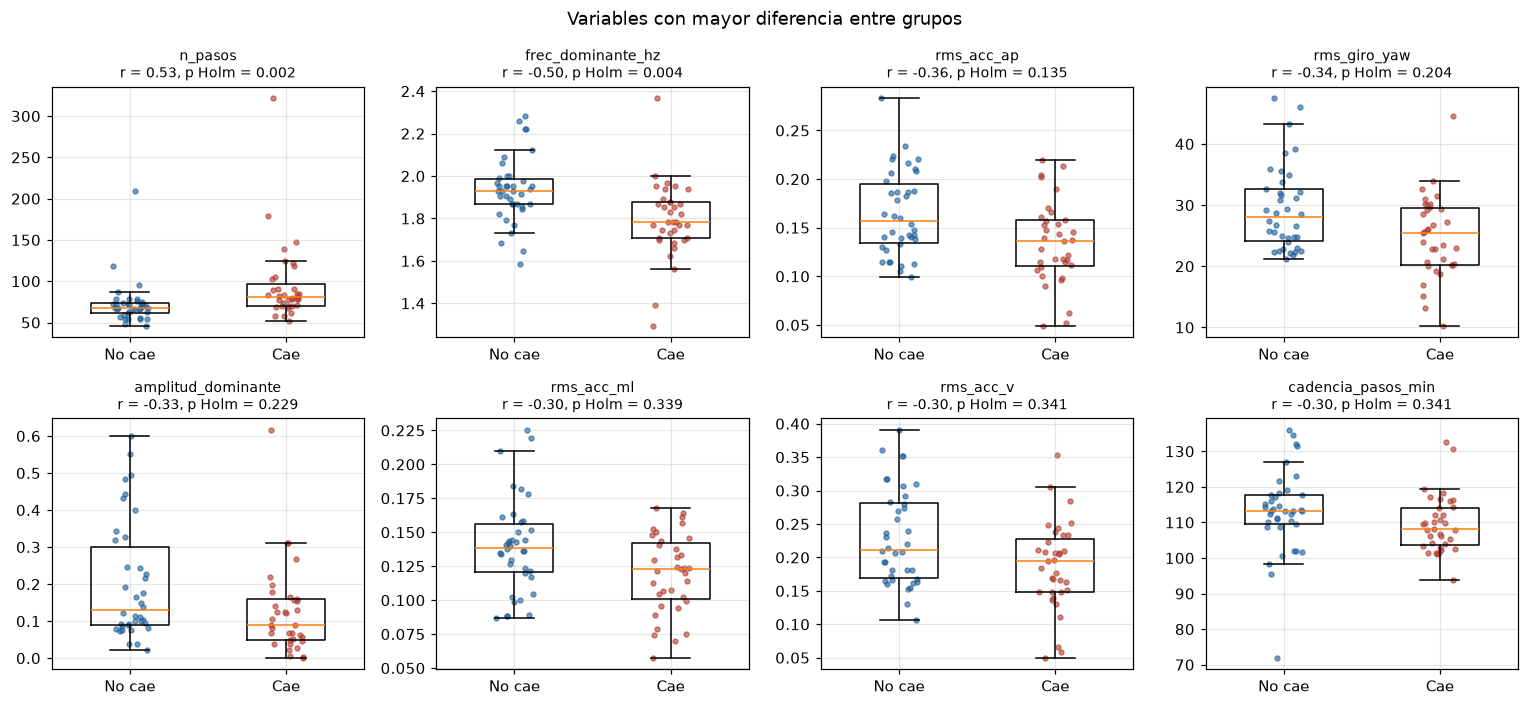

In [16]:
principales = comparacion["variable"].head(8).tolist()
fig, ejes = plt.subplots(2, 4, figsize=(14, 6.5))
rng = np.random.default_rng(SEMILLA)
for eje, v in zip(ejes.flat, principales):
    datos = [dataset.loc[dataset["grupo"] == g, v].dropna() for g in ("No cae", "Cae")]
    eje.boxplot(datos, widths=0.5, showfliers=False)
    eje.set_xticks([1, 2], ["No cae", "Cae"])
    for i, (g, d) in enumerate(zip(("No cae", "Cae"), datos), start=1):
        eje.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=10, alpha=0.6, color=COLORES[g])
    fila = comparacion.set_index("variable").loc[v]
    eje.set_title(f"{v}\nr = {fila['efecto_r']:.2f}, p Holm = {fila['p_holm']:.3f}", fontsize=9)
fig.suptitle("Variables con mayor diferencia entre grupos")
fig.tight_layout()
fig.savefig(FIGURAS / "variables_por_grupo.png", dpi=150)

### 6.4 Correlación entre variables

Variables muy correlacionadas entre sí (|r| > 0,9) aportan casi la misma información. Conviene tenerlo en cuenta al elegir las entradas de los modelos, sobre todo con pocas personas.

Pares con |r| > 0,9:
cadencia_pasos_min  tiempo_paso_s           -1.00
                    tiempo_zancada_s        -1.00
tiempo_paso_s       tiempo_zancada_s         1.00
cv_tiempo_paso_pct  cv_tiempo_zancada_pct    0.92
amplitud_dominante  rms_acc_v                0.94


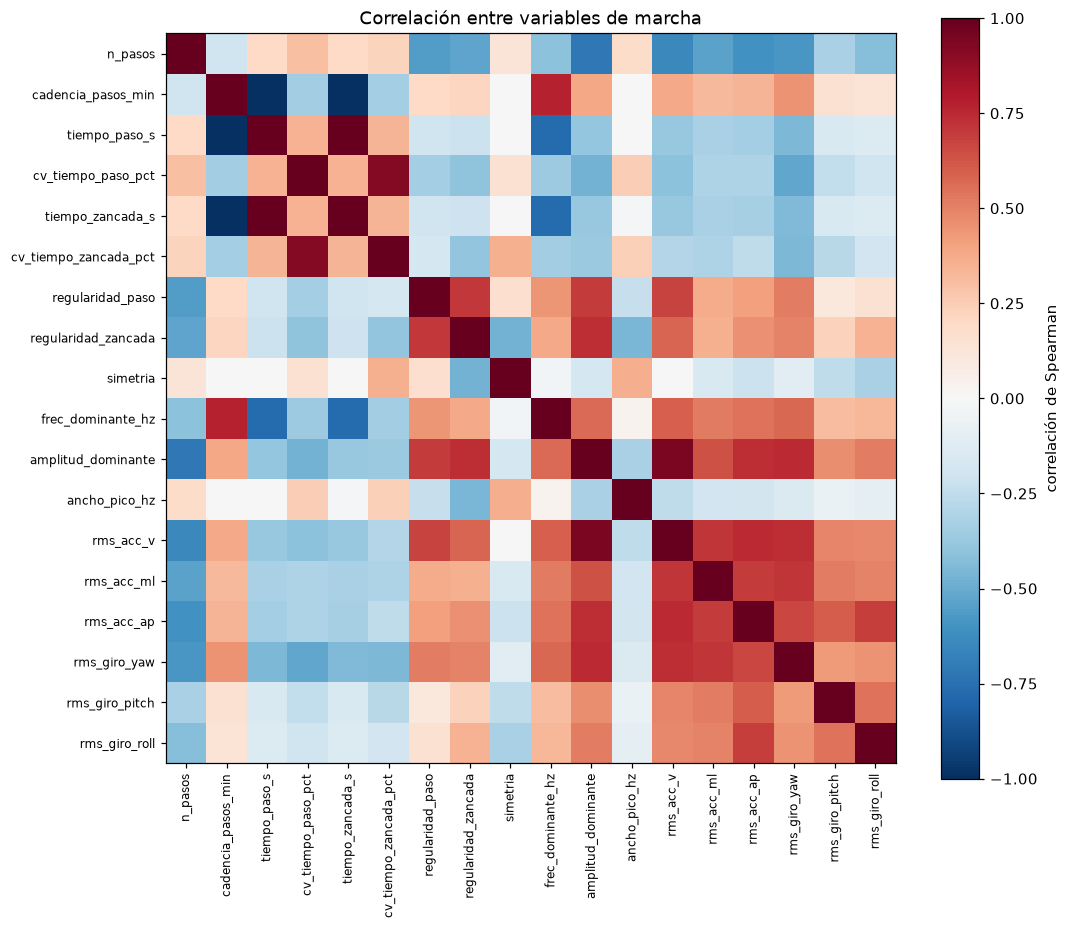

In [17]:
corr = dataset[VARIABLES].corr(method="spearman")
fig, eje = plt.subplots(figsize=(10, 8.5))
im = eje.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=90, fontsize=8)
eje.set_yticks(range(len(VARIABLES)), VARIABLES, fontsize=8)
eje.grid(False)
fig.colorbar(im, label="correlación de Spearman")
eje.set_title("Correlación entre variables de marcha")
fig.tight_layout()
fig.savefig(FIGURAS / "correlacion.png", dpi=150)

pares = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
print("Pares con |r| > 0,9:")
print(pares[pares.abs() > 0.9].round(2).to_string() if (pares.abs() > 0.9).any() else "  ninguno")

### 6.5 Vista general (PCA)

El análisis de componentes principales proyecta todas las variables en dos ejes. Si los grupos aparecen muy mezclados, es una señal temprana de que clasificarlos será difícil y de que habrá que cuidar el sobreajuste.

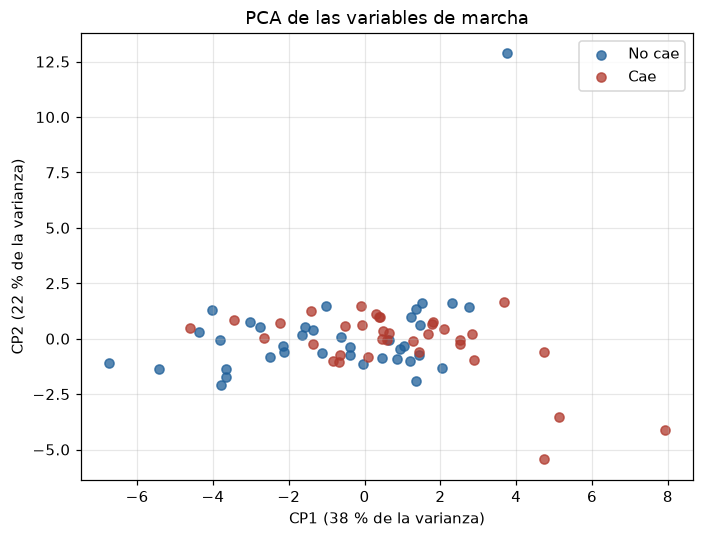

In [18]:
X = dataset[VARIABLES].dropna()
Z = (X - X.mean()) / X.std(ddof=0)
U, S, Vt = np.linalg.svd(Z.to_numpy(), full_matrices=False)
componentes = U[:, :2] * S[:2]
varianza = S ** 2 / np.sum(S ** 2)
fig, eje = plt.subplots(figsize=(6.5, 5))
for g in ("No cae", "Cae"):
    m = dataset.loc[X.index, "grupo"].to_numpy() == g
    eje.scatter(componentes[m, 0], componentes[m, 1], color=COLORES[g], label=g, alpha=0.75)
eje.set(xlabel=f"CP1 ({100 * varianza[0]:.0f} % de la varianza)",
        ylabel=f"CP2 ({100 * varianza[1]:.0f} % de la varianza)", title="PCA de las variables de marcha")
eje.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "pca.png", dpi=150)

## 7. Resumen para el informe

* **Datos:** se cargaron 73 registros (38 no caen, 35 caen); no se excluyó ninguno, ya que todos pasaron el control de calidad. La planilla clínica se asoció a 69 de los 73 registros.
* **Limpieza:** recorte de 3 s por lado, filtro pasa bajo de 20 Hz y eliminación de la gravedad. Duración útil media: 45,1 s (39,1 s en quienes no caen y 51,8 s en quienes caen).
* **Variables:** se calcularon 18 variables por persona (temporales, de regularidad, frecuenciales y de intensidad).
* **Muestra:** los grupos son comparables en edad (78,6 ± 4,9 y 77,8 ± 5,0 años; p = 0,649) y en proporción de mujeres (63,2 % y 62,9 %; p = 1,000).
* **Hallazgos del EDA:** las variables de marcha con mayor diferencia entre grupos fueron la frecuencia dominante (1,93 Hz en quienes no caen y 1,78 Hz en quienes caen; r = −0,50; p Holm = 0,004), el RMS de la aceleración anteroposterior (0,157 y 0,137 g; r = −0,36) y el RMS de la velocidad angular en yaw (28,0 y 25,4 °/s; r = −0,34). Quienes caen tienen menor cadencia y menor movimiento del tronco, lo que sugiere una marcha más lenta y cautelosa. Solo la frecuencia dominante es significativa tras la corrección de Holm.
* **Observaciones:** `n_pasos` no se usará como variable, porque depende de la duración del registro. El CV del tiempo de paso tiene valores extremos (hasta 206 %) por pausas o giros que afectan la detección de pasos. En el PCA los grupos se superponen (CP1 = 38 %, CP2 = 22 % de la varianza).
* **Limitaciones:** etiqueta retrospectiva; muestra pequeña (riesgo de sobreajuste); un solo sensor, sin velocidad ni largo de paso directos.
* **Siguiente paso (1.3):** entrenar Random Forest y XGBoost con `labwalks_variables.csv`, validando por sujeto.

In [19]:
print("Archivos generados:")
for p in sorted(list(SALIDA.glob("labwalks_*.csv")) + list(FIGURAS.glob("*.png"))):
    print(" ", p.relative_to(RAIZ))

Archivos generados:
  datos\procesados\labwalks_calidad.csv
  datos\procesados\labwalks_comparacion_grupos.csv
  datos\procesados\labwalks_variables.csv
  figuras\casia_A_ejemplos.png
  figuras\casia_B_ejemplos.png
  figuras\casia_C_ejemplos.png
  figuras\casia_inventario.png
  figuras\correlacion.png
  figuras\deteccion_pasos.png
  figuras\espectro_por_grupo.png
  figuras\limpieza_antes_despues.png
  figuras\muestra.png
  figuras\pca.png
  figuras\senales_ejemplo.png
  figuras\variables_por_grupo.png
